# Examples

This notebook shows a few examples of how to use generic temporal interval and point-interval relations and operations (e.g. testing interval relations and merging based on intervals) to implement more complex tasks.

This is demonstrated on `comu`, a proof of concept package that implements generic interval opertions on top of dataframes as well as a thin wrapper over dataframes for managing different types of events:
- point events (have an onset)
- span events (have a *span*, i.e. an onset and offset)
- state events (a series of ascending onsets that partition the entire piece)

In addition, a `Score` is essentially a dictionary containing point, span, and partition series, with a extra methods for working with them (e.g. plotting).

In [1]:
import comu
from comu import StateEvents, PointEvents, Score, SpanEvents
from comu.notation import read_comu

import pitchtypes as pt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fractions import Fraction as F

## Example 1: Group Notes by Chord Labels

Create an example score with notes (spans) and chord labels (partition)

The chord labels could also be span events (e.g. if we want to represent gaps),
which does not substantially change the code below.
Note that a partition is plotted as a series of onsets.
Each partition event is valid from it's own onset until the next,
making sure that events don't have gaps and don't overlap.

Score:
-notes: <SpanEvents> notes
         span pitch
0    [0, 3/2)    C4
1  [3/2, 5/2)    E4
2    [5/2, 3)    D4
3      [3, 4)    B3
4      [4, 5)    C4
-labels: <StateEvents> labels
  onset label
0     0     C
1     2    G7
2     4     C


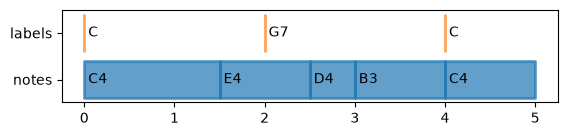

In [2]:
notes = SpanEvents(
    pd.DataFrame(
        {
            "span": comu.IntervalArray.from_breaks([F(0), F(1.5), F(2.5), F(3), F(4), F(5)]),
            "pitch": [pt.SpelledPitch(p) for p in ["C4", "E4", "D4", "B3", "C4"]],
        }
    )
)

chords = StateEvents(
    pd.DataFrame({"onset": [F(0), F(2), F(4)], "label": ["C", "G7", "C"]})
)  # .spans(5)

score = Score({"notes": notes, "labels": chords})
print(score)
# fig, ax = plt.subplots(figsize=(6, 1))
score.plot();

To group the notes by chord label, we
1. merge the notes with the labels by a given relation (e.g. intersecting with or starting the label's span),
2. (optionally) clip the notes to the label's span,
3. grouping by label.

Merging two event series (left and right) results in a new series (with the same type as the left) onto which the right events have been merged.
That means, that the properties of the right events are avaliable as extra columns (with adjusted names in the case of conflicts).
The new event series can then be used e.g., to group by the 
Note that merging is done according to whether the relation between events on the left and on the right are satisfied,
which means that the events on the left can be duplicated if they match with several events on the right!

Here, we demonstrate this by plotting the label groups separately, wrapping each of them in another `Score` element.
This is not necessary for further analysis and only done for easier plotting here.

In [3]:
def by_chords(score, include="intersects", clip=False):
    # merge notes with labels
    notes_with_labels = score["notes"].merge_with_spans(score["labels"].spans(score.end), by=include)

    # clip notes (optional)
    if clip:
        notes_with_labels = notes_with_labels.clip("span_labels")

    return notes_with_labels


def plot_groups(notes_with_labels, score):
    # Group merged events by label (via the onset column, which is unique).
    groups = notes_with_labels.events.groupby("onset")

    # For visualization, create a new score for each group.
    n_labels = len(score["labels"].events)
    fig, ax = plt.subplots(
        n_labels, 1, sharex=True, figsize=(6, n_labels), layout="compressed"
    )

    # Convert labels to spans so that we can show them individually.
    # If labels were already encoded as spans, we wouldn't need .spans() here.
    # score.end represents the latest time point in the score
    # and serves as the offset of the last label span.
    label_spans = score["labels"].spans(score.end).events

    for i, (onset, group) in enumerate(groups):
        gscore = comu.Score()
        gscore["notes"] = group.as_spans  # .as_spans is a "dataframe accessor"
        gscore["labels"] = label_spans[label_spans["onset"] == onset].as_spans
        # print(gscore)
        gscore.plot(ax[i])

Interval relations that we can use to merge on include `"intersects"` for any kind of overlap, `"starts_in"`, `"ends_in"`, or `"during"`.
Here is the full list of possible values.
You can also provide a list of relations which are treated as a disjunction (i.e. at least of them needs to be satisfied).

In [4]:
comu.interval_relations.IntervalRelation

typing.Literal['precedes', 'follows', 'meets', 'is_met', 'overlaps', 'is_overlapped', 'starts', 'is_started', 'contains_strict', 'during_strict', 'finishes', 'is_finished', 'equal', 'intersects', 'contains', 'during', 'contains_start', 'starts_in', 'contains_end', 'ends_in', 'starts_with', 'ends_with']

<SpanEvents> 
          span pitch onset label span_labels
0     [0, 3/2)    C4     0     C      [0, 2)
3   [3/2, 5/2)    E4     0     C      [0, 2)
4   [3/2, 5/2)    E4     2    G7      [2, 4)
7     [5/2, 3)    D4     2    G7      [2, 4)
10      [3, 4)    B3     2    G7      [2, 4)
14      [4, 5)    C4     4     C      [4, 5)


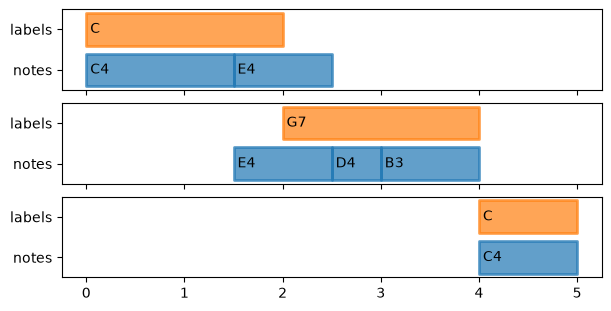

In [5]:
notes_with_chords = by_chords(score)
print(notes_with_chords) # shows the merged event series
plot_groups(notes_with_chords, score)

Note how E4 is duplicated here because it intersects with two chord labels.
If we don't want that, we could pick a different inclusion relation:

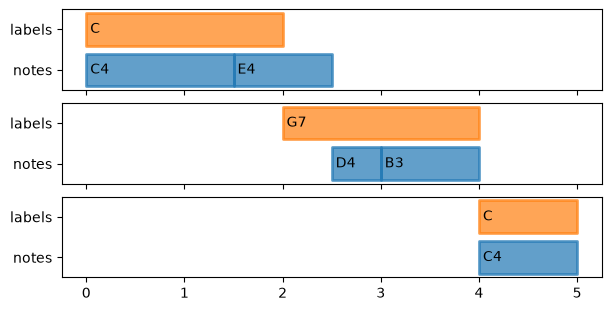

In [6]:
plot_groups(by_chords(score, include="starts_in"), score)

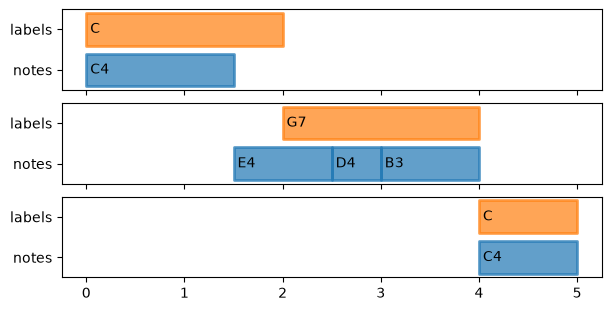

In [7]:
plot_groups(by_chords(score, include="ends_in"), score)

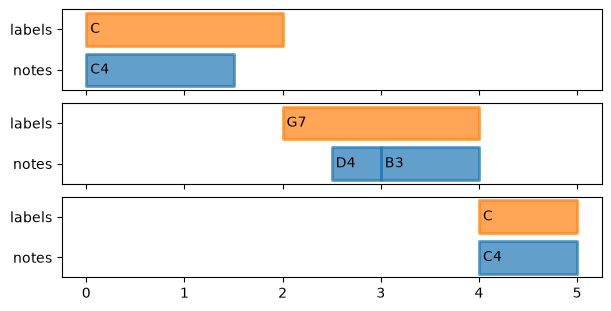

In [8]:
# this even drops E4
plot_groups(by_chords(score, include="during"), score)

If you want, you can clip the notes to their label span.
This might be useful if you need the duration of a note under its label (e.g. for duration weighted pitch profiles).

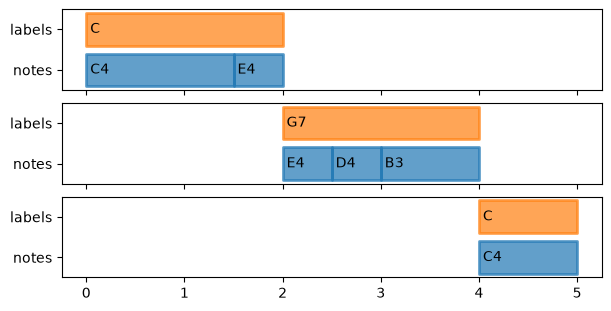

In [9]:
# clip notes to label span
plot_groups(by_chords(score, clip=True), score)

## Example 2: Absolute Pitch to Key-Relative Pitch Class

In this example, we want to express the pitch of notes as interval classes to the root of the local key.

We start with the notes from above and define an event partition of key regions, represented by the root (tonal pitch class).

Score:
-notes: <SpanEvents> notes
         span pitch
0    [0, 3/2)    C4
1  [3/2, 5/2)    E4
2    [5/2, 3)    D4
3      [3, 4)    B3
4      [4, 5)    C4
-keys: <StateEvents> keys
  onset root
0     0    C
1     2    G
2     4    C


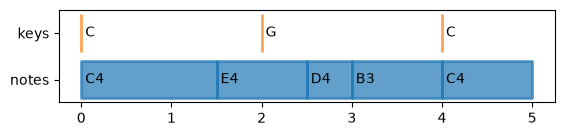

In [10]:
keys = comu.StateEvents(
    pd.DataFrame(
        {"onset": [F(0), F(2), F(4)], "root": [pt.SpelledPitchClass(p) for p in ["C", "G", "C"]]}
    )
)
score = comu.Score({"notes": notes, "keys": keys})
print(score)
score.plot();

We merge the notes with the key regions they start in.
Then we use the root column to compute the relative pitch.

In [11]:
# merge notes with keys
rel_notes = score["notes"].merge_with_spans(score["keys"].spans(score.end), by="starts_in").events

# convert pitch to relative by subtracting the root
rel_notes["pitch"] = rel_notes.apply(
     lambda row: row["pitch"].to_class() - row["root"], axis=1
)

rel_notes

,span,pitch,onset,root,span_keys
0,"[0, 3/2)",P1,0,C,"[0, 2)"
3,"[3/2, 5/2)",M3,0,C,"[0, 2)"
7,"[5/2, 3)",P5,2,G,"[2, 4)"
10,"[3, 4)",M3,2,G,"[2, 4)"
14,"[4, 5)",P1,4,C,"[4, 5)"


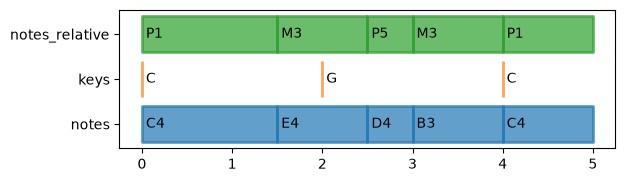

In [12]:
# add relative notes to score and plot
score["notes_relative"] = rel_notes.as_spans
score.plot();

## Example 3: Unfold Repetitions

Repetition structure can be represented by a combination of sections (spans) and a sequence of section labels representing a specific unfolding.

For this example, we are going to create the score by reading an exterimental notation that is something between TSV and humdrum.
The code for it is still very basic:
it only reads data as strings, so we'll have to parse pitches separately if we want to use them as such,
and rename some generic columns.

Score:
-notes: <SpanEvents> notes
         span pitch  id
0  [1/4, 3/8)    C4  n1
1  [3/8, 3/4)    D4  n2
2    [1, 9/8)    B3  n3
3  [9/8, 3/2)    C4  n4
4    [7/4, 2)    B3  n5
5    [2, 5/2)    C4  n6
-sections: <SpanEvents> sections
         span section
0    [0, 1/2)       A
1  [3/4, 5/4)  volta1
2  [3/2, 5/2)  volta2


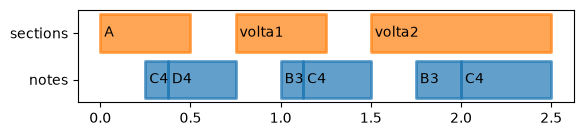

In [13]:
# create a score from a TSV-like notation
score = read_comu("""
---
[spines.notes]
type = "pitch"
[spines.sections]
type = "section"
---
notes	id(notes)	sections
4:.	.	2:A
8:C4	n1	.
4.:D4	n2	.
4:.	.	2:volta1
8:B3	n3	.
4.:C4	n4	.
4:.	.	1:volta2
4:B3	n5	.
2:C4	n6	.
""", keep_tokens = False)
score.plot()
print(score)

order = ["A", "volta1", "A", "volta2"]

Note how the segments are note directly ajacent and there are notes reaching out of the segments.
That's because this representation only contains the building blocks for the unfolded score.
The actual score is obtained by shifting and concatenating the notes in each segment.

We'll do this in several steps.
First, we merge the notes with the sections to find out which notes belong to which section.

In [14]:
section_notes = score["notes"].merge_with_spans(score["sections"])
section_notes.events

,span,pitch,id,span_sections,section
0,"[1/4, 3/8)",C4,n1,"[0, 1/2)",A
3,"[3/8, 3/4)",D4,n2,"[0, 1/2)",A
7,"[1, 9/8)",B3,n3,"[3/4, 5/4)",volta1
10,"[9/8, 3/2)",C4,n4,"[3/4, 5/4)",volta1
14,"[7/4, 2)",B3,n5,"[3/2, 5/2)",volta2
17,"[2, 5/2)",C4,n6,"[3/2, 5/2)",volta2


Second, we group by section, keeping track of each groups section name and span.
The groups are stored in a dictionary where we can look up each sections span and notes.

In [15]:
section_groups = {
    label: (sec_span, notes)  for (label, sec_span), notes in section_notes.events.groupby(["section", "span_sections"])
}
section_groups

{'A': ([0, 1/2),
           span pitch  id span_sections section
  0  [1/4, 3/8)    C4  n1      [0, 1/2)       A
  3  [3/8, 3/4)    D4  n2      [0, 1/2)       A),
 'volta1': ([3/4, 5/4),
            span pitch  id span_sections section
  7     [1, 9/8)    B3  n3    [3/4, 5/4)  volta1
  10  [9/8, 3/2)    C4  n4    [3/4, 5/4)  volta1),
 'volta2': ([3/2, 5/2),
          span pitch  id span_sections section
  14  [7/4, 2)    B3  n5    [3/2, 5/2)  volta2
  17  [2, 5/2)    C4  n6    [3/2, 5/2)  volta2)}

Finally, the groups are used to assemble the unfolded score.
For each section in the `order`, we look up the section,
shift the notes so that the new section starts right after the previous,
and concatenate all notes into a single event series again.

We combine all of these steps in a function to make the code easier to reuse.

In [16]:
def unfold(score, what, order):
    # find corresponding sections through merge
    section_events = score[what].merge_with_spans(score["sections"])

    # group by section and collect in dictionary for lookup
    section_groups = {
        label: (sec_span, notes)
        for (label, sec_span), notes in section_events.events.groupby(
            ["section", "span_sections"]
        )
    }

    # unfold: go through section labels in 'order', shift segment, and append
    time = 0
    sections_in_order = []
    for label in order:
        sec_span, segment = section_groups[label]
        shifted_segment = segment.assign(span=segment["span"] + (time - sec_span.left))
        time += sec_span.duration  # update time
        sections_in_order.append(shifted_segment)

    # concatenate shifted segments
    return pd.concat(sections_in_order).as_spans

We can now use this `unfold()` function to unfold the note events according to some order of sections.
If we apply `unfold()` to the sections themselves, they will be put in the unfolded order!

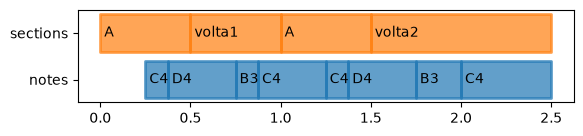

In [17]:
unfolded_notes = unfold(score, "notes", order)
unfolded_sections = unfold(score, "sections", order)
Score({"notes": unfolded_notes, "sections": unfolded_sections}).plot();

Here is a little helper function that unfoldes all event series in a score:

In [18]:
def unfold_all(score, order):
    new_score = Score()
    for series in score:
        new_score[series] = unfold(score, series, order)
    return new_score

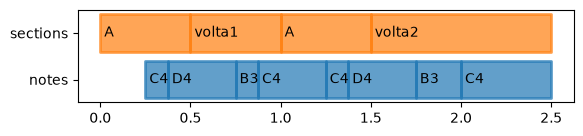

In [19]:
unfold_all(score, order).plot();

If we want a seconda-volta version of the piece, we can use the corresponding section order:

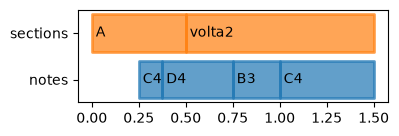

In [20]:
unfold_all(score, ["A", "volta2"]).plot(figsize=(4, 1.2));

What if A is repeated three times, going into the first ending twice?
That's again expressed by a different section order.

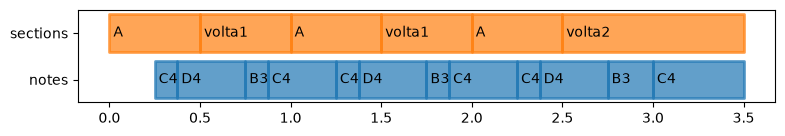

In [21]:
unfold_all(score, ["A", "volta1", "A", "volta1", "A", "volta2"]).plot(figsize=(9, 1.2));

## Example 4: Monophony Check

What if we want to make sure that the notes in a piece are monophonic, i.e. that they don't overlap?
This is simply a matter of sorting the events by onset and making sure that the offset of one note does not overlap with the onset of the next.

Score:
-notes: <SpanEvents> notes
       span token
0    [0, 1)    C4
1  [1/2, 2)    C4
2    [2, 3)    C4

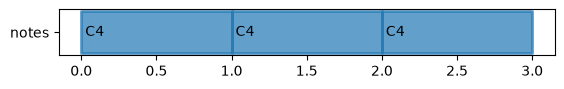

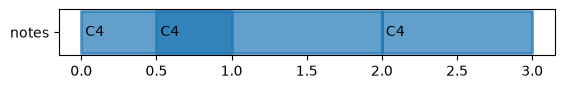

In [22]:
score_mono = comu.notation.read_comu("""
notes
1:C4
1:C4
1:C4
""")
score_mono.plot()

# Here we use an explicit time column.
# it's time value is used as the duration of the row
# instead of the shortest event duration in the row.
score_non_mono = comu.notation.read_comu("""
time	notes
2	1:C4
1.	1.:C4
1	1:C4
""")
score_non_mono.plot();
score_non_mono

In [23]:
def spans_are_mono(events):
    spans = events.events["span"].sort_values().array
    onsets = spans.left
    offsets = spans.right
    return (offsets[:-1] <= onsets[1:]).all()

In [24]:
spans_are_mono(score_mono["notes"])

np.True_

In [25]:
spans_are_mono(score_non_mono["notes"])

np.False_

## Example 5: Quantization

There are several ways we could quantize a set of events.
The most straightforward case is where we simply want to round the on- and offsets to a fixed grid.
Rounding to a non-integer grid can be achieved by scaling the values so that the resolution of the grid coincides with integers,
then rounding, and then scaling back down.

Suppose that note durations are expressed as fractions of whole notes (1/4 = quarter note).
If we want a eigth note grid, we can multiply durations by 8, round and then divide by 8 again:

In [26]:
def round_to_8th(x):
    return np.round(x * 8) / 8

round_to_8th(0.3)

np.float64(0.25)

We can easily apply this way of quantizing by applying `round_to_8th` to the onsets and offsets of the event spans
using `comu.interval_relations.map_interval()`.

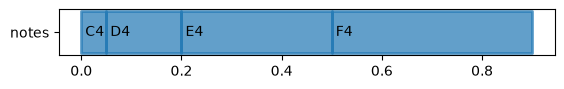

In [27]:
score_unquant = comu.notation.read_comu("""
---
time.type = "numeric"
spines.notes.type = "pitch"
---
notes
0.05:C4
0.15:D4
0.3:E4
0.4:F4
""")
score_unquant.plot();

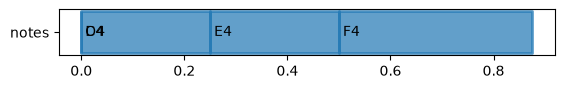

In [28]:
quant_spans = score_unquant["notes"].events["span"].array.map_time(round_to_8th)
quant_events = score_unquant["notes"].events.assign(span=quant_spans).as_spans
Score({"notes": quant_events}).plot();

The above method is a bit unwieldy because it requires a lot of data plumbing to get to the event time data and pack everything back into a score.
Since manipulating the time axis of a score is a common task, score and event series types offer a method `.map_time(f)` that maps a function `f` over all time values (onsets and offsets) in the data structure.

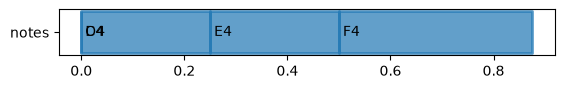

In [29]:
score_quant = score_unquant.map_time(round_to_8th)
score_quant.plot();

In the above example, the first note is collapsed to an empty interval because both its onset and offset get rounded to the same time point.
We cannot generally prevent that with `.map_time()` since it treats all time points independently.
But we can fix it in a separate post-processing step by checking for empty intervals and moving their offsets by one step:

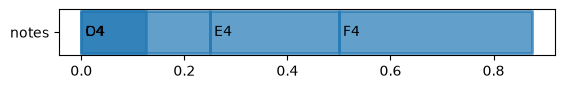

In [30]:
# get on- and offsets
spans = score_quant["notes"].events["span"].array
onsets = np.array(spans.left)
offsets = np.array(spans.right)

# modify offsets where on==off
np.putmask(offsets, offsets == onsets, offsets + 1/8)

# update spans with new offsets
score_quant["notes"].events["span"] = comu.IntervalArray.from_arrays(onsets, offsets)

score_quant.plot();

By fixing the duration of the first note, it now overlaps with the second note.
We could try to fix this by also changing the onset of the next note,
but then we might run into problems if we have a lot of notes that are smaller than the grid and start to push each other around.

Finally, we might want to map on- and offsets to a different unit, e.g. integers that we can use as indices to an array-based representation:

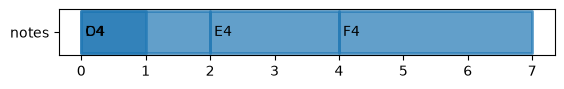

In [31]:
score_index = score_quant.map_time(lambda x: np.rint(x * 8))
score_index.plot();

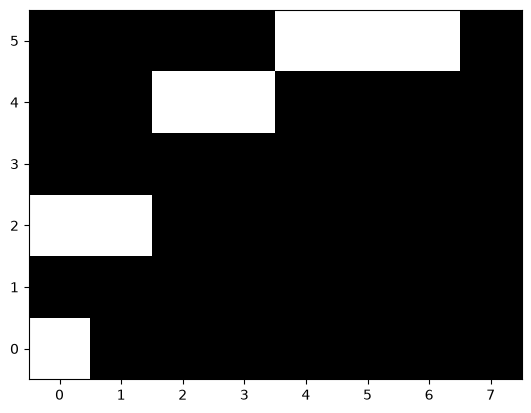

In [32]:
notes = score_index["notes"].events
pitches = notes["pitch"]
onsets = notes["span"].array.left
offsets = notes["span"].array.right

# fill a pianoroll-like binary matrix
pianoroll = np.zeros((6,8))
for pitch, on, off in zip(pitches, onsets, offsets):
    pitch = pitch.convert_to(pt.EnharmonicPitch).midi - 60
    on = int(on)
    off = int(off)
    pianoroll[pitch, on:off] = 1

plt.imshow(pianoroll, origin="lower", cmap="gray")

## Example 6: Slicing

This is a common preprocessing step:
To represent a polyphonic piece as a sequence of entities, cut it into slices wherever at least one note changes.
Within each slice, nothing changes and the set of notes is fixed.

We can achieve this by
1. collecting all note on- and offsets,
2. creating spans from the cut points (e.g. via `StateEvents`),
3. grouping notes by slice span and collecting their pitches.

Optionally, we can even detect which notes start and end in a slice,
so that we know if they are held over from / to the adjacent slices.

Score:
-notes1: <SpanEvents> notes1
       span token pitch
0  [0, 1/2)    C3    C3
1  [1/2, 1)    E2    E2
2  [1, 3/2)    F2    F2
3  [3/2, 2)    G2    G2
4  [2, 9/4)    C3    C3
-notes2: <SpanEvents> notes2
            span token pitch
0       [0, 1/4)    G3    G3
1     [1/4, 1/2)    C4    C4
2     [1/2, 3/4)    E4    E4
3       [3/4, 1)    C4    C4
4       [1, 9/8)    A3    A3
5     [9/8, 5/4)    B3    B3
6    [5/4, 11/8)    C4    C4
7   [11/8, 13/8)    B3    B3
8    [13/8, 7/4)    C4    C4
9    [7/4, 15/8)    D4    D4
10     [15/8, 2)    B3    B3
11      [2, 9/4)    C4    C4

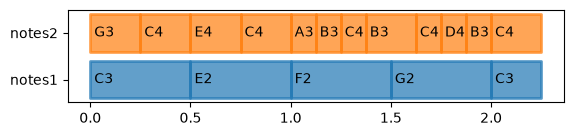

In [33]:
score = comu.notation.read_comu("""
---
spines.notes1.type = "pitch"
spines.notes2.type = "pitch"
---
notes1	notes2
2:C3	4:G3
.	4:C4
2:E2	4:E4
.	4:C4
2:F2	8:A3
.	8:B3
.	8:C4
8:.	4:B3
2:G2	8:.
.	8:C4
.	8:D4
.	8:B3
4:C3	4:C4
""")
score.plot()
score

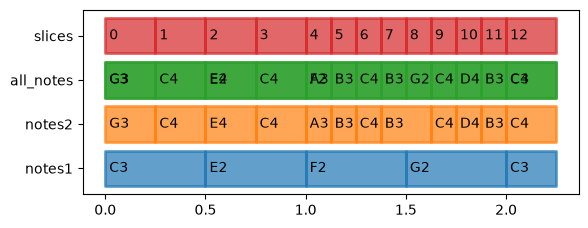

In [34]:
# combine the two note spines
all_notes = pd.concat([score["notes1"].events, score["notes2"].events])
score["all_notes"] = SpanEvents(all_notes)

# find all cut points
onsets = set(all_notes["span"].array.left)
offsets = set(all_notes["span"].array.right)
cuts = np.array(list(onsets.union(offsets)))
cuts.sort()

# compute slices
slice_spans = comu.IntervalArray.from_breaks(cuts)
score["slices"] = SpanEvents(pd.DataFrame({"span": slice_spans, "slice": np.arange(len(cuts)-1)}))

score.plot();

In [35]:
# associate notes with slices
notes_by_slice = score["all_notes"].merge_with_spans(score["slices"], "slice")

# (optional:) collect extra information about whether the notes starts / ends in the slice
note_spans = notes_by_slice.events["span"].array
slice_spans = notes_by_slice.events["span_slice"].array
notes_by_slice.events["starts"] = comu.interval_relations.starts_with(note_spans, slice_spans)
notes_by_slice.events["ends"] = comu.interval_relations.ends_with(note_spans, slice_spans)

notes_by_slice

<SpanEvents> 
             span token pitch   span_slice  slice  starts   ends
0        [0, 1/2)    C3    C3     [0, 1/4)      0    True  False
1        [0, 1/2)    C3    C3   [1/4, 1/2)      1   False   True
15       [1/2, 1)    E2    E2   [1/2, 3/4)      2    True  False
16       [1/2, 1)    E2    E2     [3/4, 1)      3   False   True
30       [1, 3/2)    F2    F2     [1, 9/8)      4    True  False
31       [1, 3/2)    F2    F2   [9/8, 5/4)      5   False  False
32       [1, 3/2)    F2    F2  [5/4, 11/8)      6   False  False
33       [1, 3/2)    F2    F2  [11/8, 3/2)      7   False   True
47       [3/2, 2)    G2    G2  [3/2, 13/8)      8    True  False
48       [3/2, 2)    G2    G2  [13/8, 7/4)      9   False  False
49       [3/2, 2)    G2    G2  [7/4, 15/8)     10   False  False
50       [3/2, 2)    G2    G2    [15/8, 2)     11   False   True
64       [2, 9/4)    C3    C3     [2, 9/4)     12    True   True
65       [0, 1/4)    G3    G3     [0, 1/4)      0    True   True
79     [1/4

In [36]:
# collect pitches in each slice
sliced_notes = notes_by_slice.events.groupby(["slice", "span_slice"])[["pitch"]].agg(list)

# move span index to column, to be able to wrap it in a SpanEvents again
sliced_notes = sliced_notes.reset_index(level="span_slice", names=["index", "span"])
sliced_notes

,span,pitch
slice,,
0,"[0, 1/4)","[C3, G3]"
1,"[1/4, 1/2)","[C3, C4]"
2,"[1/2, 3/4)","[E2, E4]"
3,"[3/4, 1)","[E2, C4]"
4,"[1, 9/8)","[F2, A3]"
5,"[9/8, 5/4)","[F2, B3]"
6,"[5/4, 11/8)","[F2, C4]"
7,"[11/8, 3/2)","[F2, B3]"
8,"[3/2, 13/8)","[G2, B3]"


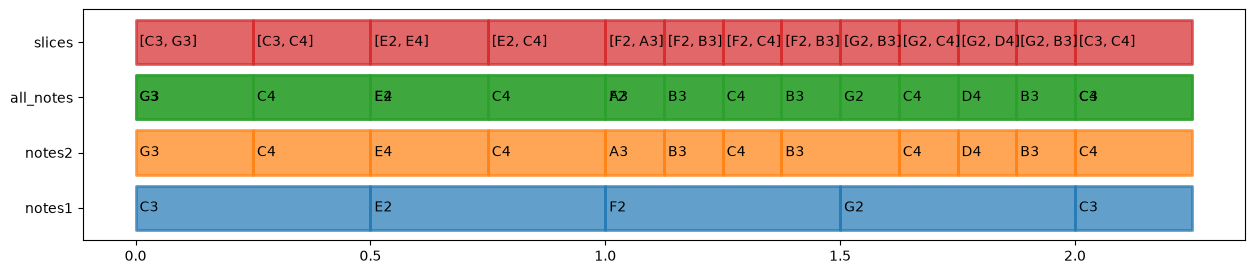

In [37]:
score["slices"] = SpanEvents(sliced_notes)
score.plot(figsize=(15,3));

## Example 7: Time Signatures and Meter

In this example, we have a look at parsimonious representations of measures, time signatures, and meter.
- Meters are represented as states, i.e. regions that have a common time signature.
  - The beginning of the region serves as the downbeat of the meter.
  - We can specify an optional offset (for pickups) between the beginning of the region and the downbeat.
- Measures follow from the time-signature regions and their meter. One measure corresponds to one metrical cycle
  - Measures can be incomplete at the beginning or end of a region, but we can check that.
- The metrical weight of a note follows from its position relative to the active meter.

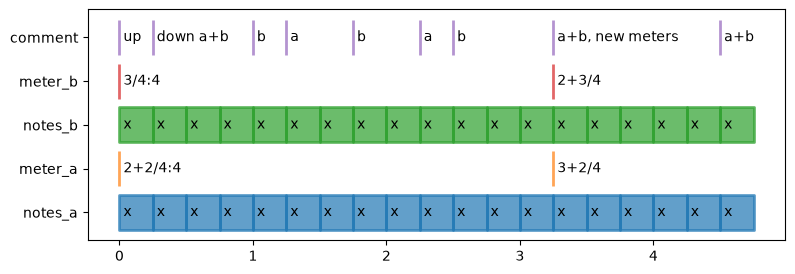

In [38]:
with open("meter_example.comu") as f:
    score = comu.notation.read_comu(f.read())

score.plot(figsize=(9,3));

### Representing Meter

The first thing we can do here is parse the time signatures into meter representations.
In our example, each meter is represented by
- a beat duration, represented by the denominator,
- groups of beats (numerator)
- groups of groups (higher metrical levels).

For example, the meter `2+3/4` is interpreted as a 5/4 meter with a 2+3 grouping on the higher level.
To keep things simple, we only allow 3 hierarchical levels here: beats, level-1 groups and level-2 groups.

In [39]:
from fractions import Fraction
from dataclasses import dataclass

@dataclass(frozen=True, order=True)
class Meter:
    beat: Fraction  # base duration
    groups: tuple   # group sizes

    def __repr__(self):
        return "+".join(map(str, self.groups)) + '/' + str(1 / self.beat)

    @property
    def duration(self):
        return sum(self.groups) * self.beat

    @classmethod
    def from_string(cls, input):
        num, denom = input.split("/")
        groups = num.split("+")
        return Meter(Fraction(1, int(denom)), tuple(int(group) for group in groups))

# 4/4 as 2+2/4
print(Meter(F(1, 4), [2, 2]))
five = Meter.from_string("3+2/4")
print(five, "duration:", five.duration)
print(Meter.from_string("3/4"))

2+2/4
3+2/4 duration: 5/4
3/4


The meter in the file can have an additional offset, indicated by `:` and notated as a reciprocal duration (like other durations).

In [40]:
def parse_meter(input: str):
    match input.split(':'):
        case meter_str, offset_str:
            meter = Meter.from_string(meter_str)
            offset = comu.notation.parse_recip(offset_str)
        case meter_str, :
            meter = Meter.from_string(meter_str)
            offset = F(0)
    return pd.Series([meter, offset], index=["meter", "offset"])

def parse_meter_events(evs):
    parsed = evs.events["token"].apply(parse_meter)
    events = pd.concat([evs.events, parsed], axis=1)
    return events.as_states

score["meter_a"] = parse_meter_events(score["meter_a"])
score["meter_b"] = parse_meter_events(score["meter_b"])
score["meter_a"]

<StateEvents> meter_a
   onset    token  meter offset
0      0  2+2/4:4  2+2/4    1/4
1   13/4    3+2/4  3+2/4      0

### Computing Measures

We can find measures using the following procedure:
- convert meter events from states to spans
- take each span and convert it into a series of measure events
  - a non-zero offset marks an incomplete measure in the beginning
  - if the duration of the meter region (minus offset) is not a multiple of the meter, we have an incomplete measure at the end

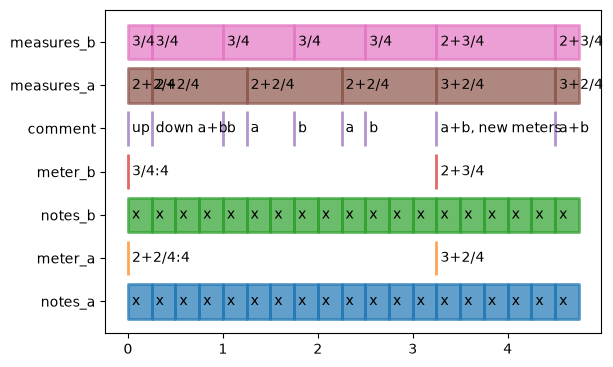

In [41]:
def meters_to_measures(meters: SpanEvents) -> SpanEvents:
    measures = []
    for _, meter_seg in meters.events.iterrows():
        start = meter_seg["span"].left
        end = meter_seg["span"].right
        offset = meter_seg["offset"]
        meter = meter_seg["meter"]
        while start < end:
            duration = meter.duration if offset == 0 else min(offset, meter.duration)
            measures.append({
                "span": comu.Interval(start, min(start + duration, end)),
                "meter": meter,
                "offset": offset,
            })
            offset = 0
            start += duration
    mevs = pd.DataFrame.from_records(measures)
    mevs["span"] = mevs["span"].astype("span")
    return mevs.as_spans

score["measures_a"] = meters_to_measures(score["meter_a"].spans(score.end))
score["measures_b"] = meters_to_measures(score["meter_b"].spans(score.end))
score.plot();

We can distinguish incomplete measures by their metrical offset.
An upbeat has a positive offset (e.g. measure 0) while an uncompleted measure has an offset of 0 but a duration that is less than the nominal duration (e.g. last measure).

In [42]:
score["measures_a"]

<SpanEvents> measures_a
          span  meter offset
0     [0, 1/4)  2+2/4    1/4
1   [1/4, 5/4)  2+2/4      0
2   [5/4, 9/4)  2+2/4      0
3  [9/4, 13/4)  2+2/4      0
4  [13/4, 9/2)  3+2/4      0
5  [9/2, 19/4)  3+2/4      0

### Computing Metrical Weight

Here, the metrical weight of a note is defined as follows:

- 3: downbeat of the first group
- 2: downbeat of any other group
- 1: non-downbeat
- 0: offbeat

In [43]:
from collections import defaultdict

def beat_map(meter: Meter) -> defaultdict[Fraction, int]:
    m = defaultdict(int)
    t = Fraction(0)
    m[t] += 1  # overall downbeat
    for g in meter.groups:
        m[t] += 1  # group downbeat
        for _ in range(g):
            m[t] += 1  # beat
            t += meter.beat
    return m

beat_map(Meter.from_string("3+2/4"))

defaultdict(int,
            {Fraction(0, 1): 3,
             Fraction(1, 4): 1,
             Fraction(1, 2): 1,
             Fraction(3, 4): 2,
             Fraction(1, 1): 1})

To find the weight of each note, we
- create a beat map for the current meter
- compute the measure-relative onset of the note
- look up the onset in the beat map

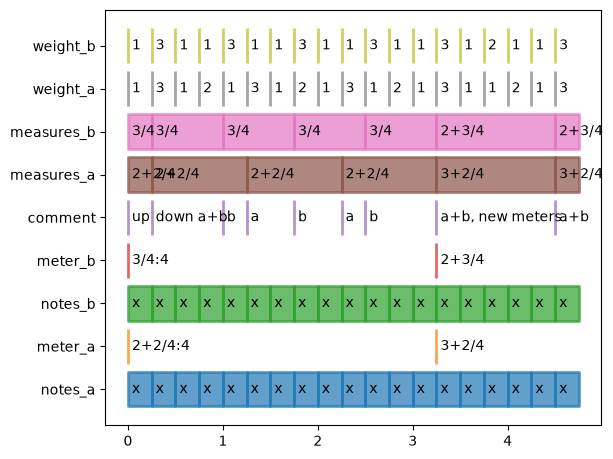

In [44]:
def metrical_weight(events: PointEvents, meters: SpanEvents):
    # merge events with meter spans
    merged = events.merge_with_spans(meters, "meter")
    # group by the meter spans, also keep each groups meter and meter offset
    groups = merged.events.groupby(["meter", "span_meter", "offset"])["onset"]
    
    def compute_weight(onsets):
        # meter, span, and offset are stored in the groups "name"
        meter, span, offset = onsets.name
        # compute measure-relative onsets
        rel_onsets = (onsets - span.left - offset) % meter.duration
        # get the metrical weight of each onset based on the beat map
        weights = rel_onsets.map(beat_map(meter))
        return weights

    weights = groups.transform(compute_weight)
    # recombine weights with onsets to create new events for the weights
    return pd.DataFrame({"onset": merged.events["onset"], "weight": weights}).as_points

score["weight_a"] = metrical_weight(score["notes_a"].onsets(), score["meter_a"].spans(score.end))
score["weight_b"] = metrical_weight(score["notes_b"].onsets(), score["meter_b"].spans(score.end))
score.plot();